# Exploratory Data Analysis: AI and Employment Anxiety on Reddit

**Time spent on this homework:** approximately 20 hours.

## Research Question

**How did discussions about AI and employment anxiety change in technology- and career-related Reddit communities between 2022 and 2024?**

## Study Overview

This exploratory data analysis examines Reddit discussions from technology-, AI-, career-, and employment-related communities between 2022 and 2024.

The analysis combines temporal, structural, engagement, and textual perspectives. We examine how discussion activity changes over time, how participation differs across communities, which employment-related AI topics become more prominent, and how the framing of AI changes across different types of Reddit communities.

Submissions and comments are analyzed separately because they represent different forms of participation: submissions introduce standalone topics, while comments reflect reactions, discussion, disagreement, and continued engagement.

## Research Hypotheses

To guide the exploratory analysis, we formulated six hypotheses about how AI-related employment discussions may have changed between 2022 and 2024.

**H1 — Structural shift in AI-and-employment discussion**  
The share of AI-and-employment discussion increased sharply after late 2022 and remained at a higher level afterwards.

**H2 — Shift from abstract to personal employment anxiety**  
Employment anxiety shifted from abstract discussions of automation in 2022 toward more personal concerns about one's own job, skills, and career in 2023–2024.

**H3 — Differences between career and technology communities**  
Career-focused communities express more personal employment anxiety, while AI- and technology-focused communities frame AI more often as a tool, opportunity, or neutral technological development.

**H4 — Shift from fear toward adaptation**  
AI-related employment discussion shifts over time from fear and uncertainty toward adaptation strategies such as reskilling, learning to use AI, and treating AI as a productivity tool.

**H5 — Growing concern about entry-level positions**  
Employment concerns increasingly focus on junior, entry-level, and new-graduate positions rather than broad claims that AI will replace entire professions.

**H6 — Relationship between anxiety and engagement**  
AI-related posts expressing employment threat or anxiety generate more discussion than opportunity-oriented or neutral AI posts.

# 0. Data Preparation and Quality Checks

Before starting the exploratory analysis, we inspected submissions and comments separately, checked field availability, duplicate IDs, missing values, and variable coverage, and selected the variables relevant to temporal, structural, engagement, and textual analysis.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("output")

submission_files = sorted(DATA_DIR.glob("RS*.csv"))
comment_files = sorted(DATA_DIR.glob("RC*.csv"))

### Common fields

In [11]:
def get_common_columns(files):
    column_sets = []

    for file in files:
        cols = set(pd.read_csv(file, nrows=0).columns)
        column_sets.append(cols)

    return sorted(set.intersection(*column_sets))


common_submission_columns = get_common_columns(submission_files)
common_comment_columns = get_common_columns(comment_files)

print("Common submission columns:", len(common_submission_columns))
print("Common comment columns:", len(common_comment_columns))

Common submission columns: 96
Common comment columns: 51


We found 96 common fields in the submission files and 51 in the comment files. For the analysis, we kept only the fields relevant to our research question.

### Dataset size and duplicate check

In [10]:
def summarize_ids(files, chunksize=200_000):
    total_rows = 0
    ids = []

    for file in files:
        for chunk in pd.read_csv(file, usecols=["id"], chunksize=chunksize):
            total_rows += len(chunk)
            ids.append(chunk["id"])

    ids = pd.concat(ids, ignore_index=True)

    return {
        "total_records": total_rows,
        "unique_ids": ids.nunique(),
        "duplicate_ids": ids.duplicated().sum()
    }


submission_summary = summarize_ids(submission_files)
comment_summary = summarize_ids(comment_files)

summary_df = pd.DataFrame(
    [submission_summary, comment_summary],
    index=["Submissions", "Comments"]
)

summary_df

,total_records,unique_ids,duplicate_ids
Submissions,2860684,2860684,0
Comments,54410195,54410195,0


No duplicate IDs were found in either submissions or comments, so no records were removed at this stage.

### Missing-value coverage

In [12]:
def calculate_coverage(files, columns, chunksize=100_000):
    known_counts = {col: 0 for col in columns}
    total_rows = 0

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=columns,
            chunksize=chunksize,
            low_memory=False
        ):
            total_rows += len(chunk)
            counts = chunk.notna().sum()

            for col in columns:
                known_counts[col] += counts[col]

    coverage = pd.DataFrame({
        "column": columns,
        "known": [known_counts[col] for col in columns]
    })

    coverage["total"] = total_rows
    coverage["missing"] = coverage["total"] - coverage["known"]
    coverage["coverage_pct"] = (
        coverage["known"] / coverage["total"] * 100
    )

    return coverage.sort_values(
        "coverage_pct",
        ascending=False
    )


submission_coverage = calculate_coverage(
    submission_files,
    common_submission_columns
)

comment_coverage = calculate_coverage(
    comment_files,
    common_comment_columns
)
print("Submission fields with lowest coverage:")
display(
    submission_coverage
    .sort_values("coverage_pct")
    .head(15)
)

print("Comment fields with lowest coverage:")
display(
    comment_coverage
    .sort_values("coverage_pct")
    .head(15)
)

In [13]:
display(
    submission_coverage
    .sort_values("coverage_pct")
    .head(15)
)

display(
    comment_coverage
    .sort_values("coverage_pct")
    .head(15)
)

,column,known,total,missing,coverage_pct
20,content_categories,0,2860684,2860684,0.000000
16,banned_by,0,2860684,2860684,0.000000
68,removed_by,0,2860684,2860684,0.000000
19,category,0,2860684,2860684,0.000000
94,view_count,0,2860684,2860684,0.000000
88,top_awarded_type,218,2860684,2860466,0.007621
25,discussion_type,280,2860684,2860404,0.009788
26,distinguished,560,2860684,2860124,0.019576
63,poll_data,2487,2860684,2858197,0.086937
6,author_flair_css_class,5288,2860684,2855396,0.184851


,column,known,total,missing,coverage_pct
2,associated_award,0,54410195,54410195,0.000000
21,comment_type,0,54410195,54410195,0.000000
47,top_awarded_type,0,54410195,54410195,0.000000
18,collapsed_because_crowd_control,0,54410195,54410195,0.000000
50,unrepliable_reason,47,54410195,54410148,0.000086
25,editable,11629,54410195,54398566,0.021373
4,author_cakeday,182237,54410195,54227958,0.334932
33,media_metadata,198303,54410195,54211892,0.364459
6,author_flair_css_class,209374,54410195,54200821,0.384807
19,collapsed_reason,468239,54410195,53941956,0.860572


Several fields have very low coverage or are completely empty. These fields were excluded from the main analysis unless they had a clear connection to the research question.

### Completely empty fields

We checked whether any fields were completely empty (`NaN` / `null`) across the whole dataset. These fields contain no observed values and were excluded from further analysis.

In [14]:
empty_submission_columns = submission_coverage[
    submission_coverage["coverage_pct"] == 0
]["column"].tolist()

empty_comment_columns = comment_coverage[
    comment_coverage["coverage_pct"] == 0
]["column"].tolist()

print("Completely empty submission fields:")
print(empty_submission_columns)

print("\nCompletely empty comment fields:")
print(empty_comment_columns)

Completely empty submission fields:
['content_categories', 'category', 'banned_by', 'removed_by', 'view_count']

Completely empty comment fields:
['collapsed_because_crowd_control', 'associated_award', 'comment_type', 'top_awarded_type']


### Fields with no variation

Some fields contain data but still have the same value in every record. Since these fields do not change across the dataset, they cannot help explain differences between posts or comments.

In [16]:
def find_constant_columns(files, columns, chunksize=100_000):
    values_seen = {col: set() for col in columns}

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=columns,
            chunksize=chunksize,
            low_memory=False
        ):
            for col in columns:
                if len(values_seen[col]) > 1:
                    continue

                values = (
                    chunk[col]
                    .astype("string")
                    .fillna("<MISSING>")
                    .unique()[:2]
                )

                values_seen[col].update(values)

    return [
        col
        for col, values in values_seen.items()
        if len(values) == 1
    ]


constant_submission_columns = find_constant_columns(
    submission_files,
    common_submission_columns
)

constant_comment_columns = find_constant_columns(
    comment_files,
    common_comment_columns
)

print("Truly constant submission fields:")
print(constant_submission_columns)

print("\nTruly constant comment fields:")
print(constant_comment_columns)

Truly constant submission fields:
['archived', 'awarders', 'banned_by', 'category', 'content_categories', 'hidden', 'is_created_from_ads_ui', 'is_meta', 'media_only', 'pinned', 'quarantine', 'removed_by', 'view_count']

Truly constant comment fields:
['associated_award', 'collapsed_because_crowd_control', 'comment_type', 'top_awarded_type']


### Selecting variables for the analysis

After removing completely empty fields and fields with no variation, the dataset still contained many variables. At this point, the main question was no longer whether a field contained data, but whether it could actually help us understand the Reddit discussions we are interested in.

We therefore reviewed the remaining variables more closely and focused on those that could describe:
- when the discussion happened;
- where it happened;
- what users wrote;
- how other users reacted to it;
- and what type of content or moderation context surrounded the discussion.

Fields that were mostly technical, weakly related to the research question, or too sparse to support meaningful analysis were not included in the main dataset.

**Submission variables selected for the main analysis:**
- `id`
- `created_utc`
- `author`
- `subreddit`
- `subreddit_subscribers`
- `title`
- `selftext`
- `score`
- `num_comments`
- `upvote_ratio`
- `is_self`
- `domain`
- `url_overridden_by_dest`
- `link_flair_text`
- `post_hint`
- `removed_by_category`
- `locked`

**Optional submission variables:**
- `author_flair_text`
- `poll_data`

**Comment variables selected for the main analysis:**
- `id`
- `created_utc`
- `author`
- `subreddit`
- `body`
- `score`
- `controversiality`
- `is_submitter`
- `link_id`
- `parent_id`
- `locked`
- `collapsed`

This step reduced the large set of Reddit metadata to a smaller group of variables that can directly contribute to the analysis of AI, employment anxiety, community differences, and engagement.

# 1. Overview

We begin with a general look at the dataset: its size, time coverage, and how the number of submissions and comments changes over time.

## 1.1 Dataset summary

First, we summarize the basic structure of the dataset to understand its overall scale and coverage.

In [17]:
def get_basic_overview(files, chunksize=200_000):
    subreddits = set()
    min_date = None
    max_date = None

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["created_utc", "subreddit"],
            chunksize=chunksize,
            low_memory=False
        ):
            dates = pd.to_datetime(
                pd.to_numeric(chunk["created_utc"], errors="coerce"),
                unit="s",
                utc=True,
                errors="coerce"
            )

            valid_dates = dates.dropna()

            if not valid_dates.empty:
                current_min = valid_dates.min()
                current_max = valid_dates.max()

                min_date = current_min if min_date is None else min(min_date, current_min)
                max_date = current_max if max_date is None else max(max_date, current_max)

            subreddits.update(
                chunk["subreddit"].dropna().astype(str).unique()
            )

    return {
        "subreddits": len(subreddits),
        "first_date": min_date,
        "last_date": max_date
    }


submission_overview = get_basic_overview(submission_files)
comment_overview = get_basic_overview(comment_files)

In [18]:
overview_df = pd.DataFrame({
    "Submissions": [
        submission_summary["total_records"],
        submission_overview["subreddits"],
        submission_overview["first_date"].strftime("%Y-%m-%d"),
        submission_overview["last_date"].strftime("%Y-%m-%d")
    ],
    "Comments": [
        comment_summary["total_records"],
        comment_overview["subreddits"],
        comment_overview["first_date"].strftime("%Y-%m-%d"),
        comment_overview["last_date"].strftime("%Y-%m-%d")
    ]
}, index=[
    "Total records",
    "Number of subreddits",
    "Earliest observed date",
    "Latest observed date"
])

overview_df

,Submissions,Comments
Total records,2860684,54410195
Number of subreddits,29,28
Earliest observed date,2022-01-01,2022-01-01
Latest observed date,2024-12-31,2024-12-31


The dataset contains 2,860,684 submissions and 54,410,195 comments collected from January 1, 2022 to December 31, 2024. Submissions come from 29 subreddits, while comments are available for 28 subreddits.

## 1.2 Activity over time

To understand how Reddit activity changed during 2022–2024, we first examined the monthly number of submissions and comments.

In [20]:
def count_records_by_month(files, chunksize=200_000):
    monthly_counts = {}

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["created_utc"],
            chunksize=chunksize
        ):
            dates = pd.to_datetime(
                pd.to_numeric(chunk["created_utc"], errors="coerce"),
                unit="s",
                utc=True,
                errors="coerce"
            )

            months = (
                dates.dropna()
                .dt.tz_localize(None)
                .dt.to_period("M")
                .astype(str)
            )
            counts = months.value_counts()

            for month, count in counts.items():
                monthly_counts[month] = monthly_counts.get(month, 0) + count

    return (
        pd.DataFrame(
            monthly_counts.items(),
            columns=["month", "count"]
        )
        .sort_values("month")
        .reset_index(drop=True)
    )


monthly_submissions = count_records_by_month(submission_files)
monthly_comments = count_records_by_month(comment_files)


In [21]:
display(monthly_submissions)
display(monthly_comments)

,month,count
0,2022-01,111432
1,2022-02,76479
2,2022-03,80790
3,2022-04,76626
4,2022-05,74892
5,2022-06,72659
6,2022-07,74643
7,2022-08,78447
8,2022-09,67736
9,2022-10,67607


,month,count
0,2022-01,2694103
1,2022-02,1813282
2,2022-03,1789744
3,2022-04,1962052
4,2022-05,1694457
5,2022-06,1688247
6,2022-07,1765495
7,2022-08,1702069
8,2022-09,1446030
9,2022-10,1499121


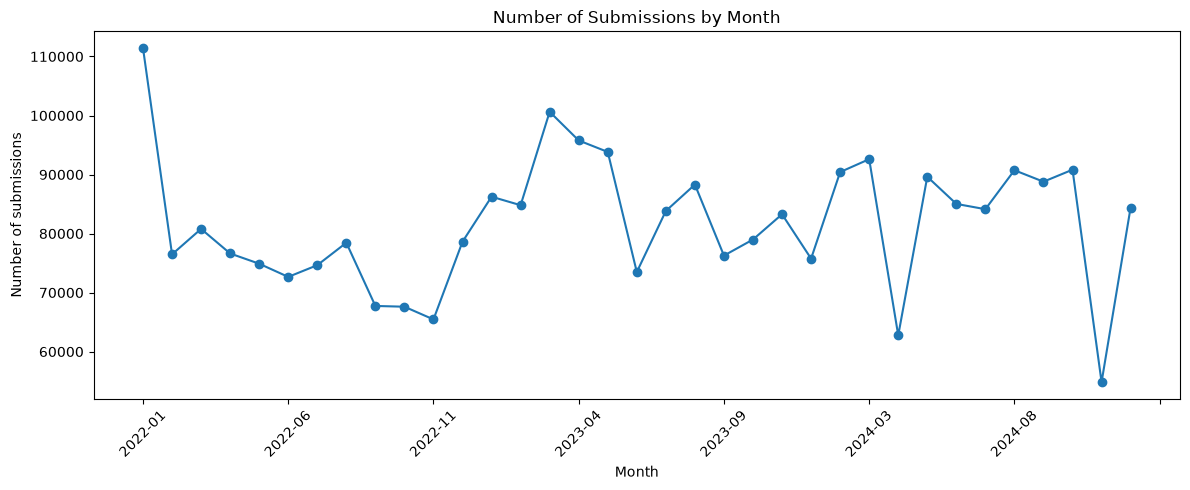

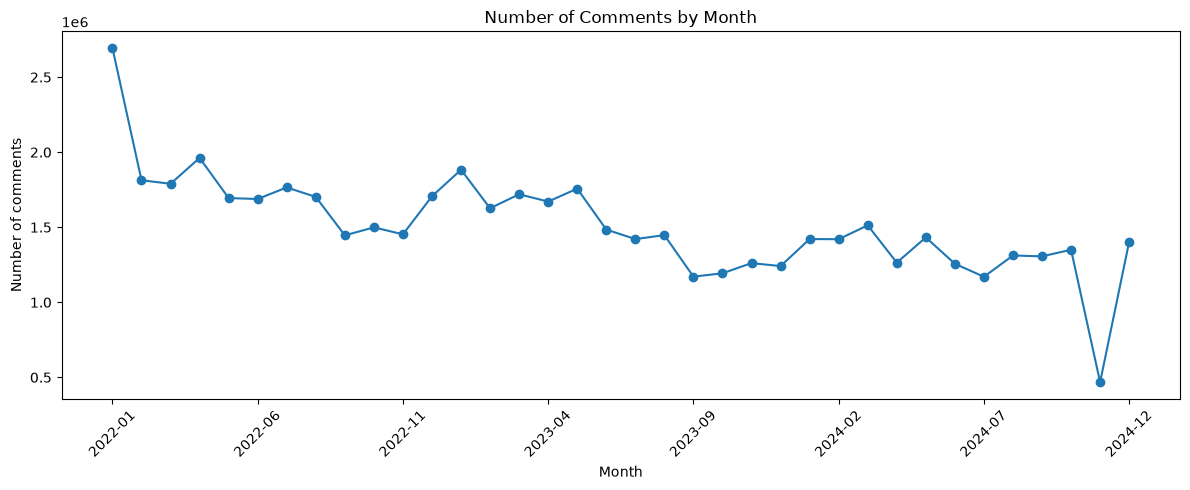

In [22]:
import matplotlib.pyplot as plt

ax = monthly_submissions.plot(
    x="month",
    y="count",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False
)

ax.set_title("Number of Submissions by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of submissions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ax = monthly_comments.plot(
    x="month",
    y="count",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False
)

ax.set_title("Number of Comments by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of comments")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

Submission and comment activity show similar broad patterns, while the number of comments is much larger throughout the whole period.

Both series start at a relatively high level in January 2022 and then decline during 2022. Submission activity rises again around early 2023 and remains relatively high afterward, although with stronger month-to-month fluctuations. Comment activity follows a smoother pattern, but it also shows an overall decline from the beginning of 2022 toward 2023–2024.

Because a decrease is visible in both submissions and comments, we will examine this pattern further instead of immediately interpreting it as a real decline in interest or participation.

A particularly sharp drop appears near the end of 2024 in both series, followed by a recovery in December. This may indicate a data-coverage or collection issue and should be checked before drawing conclusions from it.

# 2. Activity and Distribution

In the previous section, we looked at how overall Reddit activity changed over the full 2022–2024 period. We now look more closely at how this activity is distributed across different subreddits and users.

This helps us understand which communities contribute most to the dataset and whether some subreddits are more active in creating posts or in generating discussion through comments.

## 2.1 Most active subreddits

We first compare the number of submissions and comments across subreddits to see which communities contribute the most activity to the dataset.

In [ ]:
def count_by_subreddit(files, chunksize=200_000):
    counts = {}

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["subreddit"],
            chunksize=chunksize,
            low_memory=False
        ):
            value_counts = chunk["subreddit"].value_counts()

            for subreddit, count in value_counts.items():
                counts[subreddit] = counts.get(subreddit, 0) + count

    return (
        pd.DataFrame(
            counts.items(),
            columns=["subreddit", "count"]
        )
        .sort_values("count", ascending=False)
        .reset_index(drop=True)
    )


submissions_by_subreddit = count_by_subreddit(submission_files)
comments_by_subreddit = count_by_subreddit(comment_files)


,subreddit,count
0,antiwork,416119
1,careerguidance,332111
2,ChatGPT,290410
3,jobs,255761
4,cscareerquestions,169039
5,technology,166541
6,learnprogramming,148713
7,webdev,140639
8,resumes,100614
9,recruitinghell,89169


,subreddit,count
0,antiwork,17687629
1,technology,9722735
2,ChatGPT,3349882
3,Futurology,3219885
4,jobs,2578825
5,cscareerquestions,2436828
6,singularity,2071671
7,careerguidance,2017798
8,recruitinghell,1956494
9,learnprogramming,1230201


In [24]:
submissions_by_subreddit = submissions_by_subreddit.rename(
    columns={"count": "submissions"}
)

comments_by_subreddit = comments_by_subreddit.rename(
    columns={"count": "comments"}
)

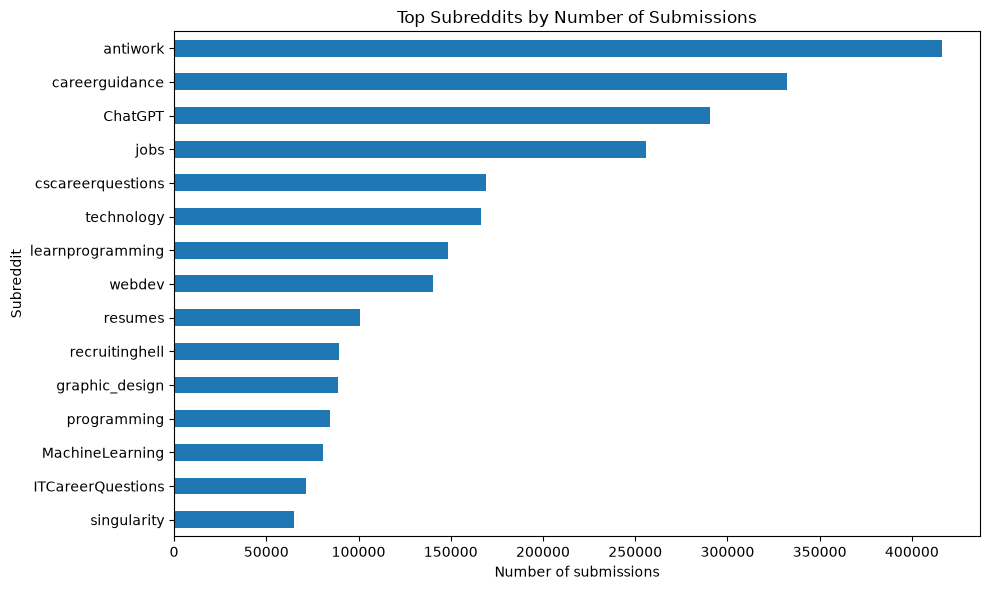

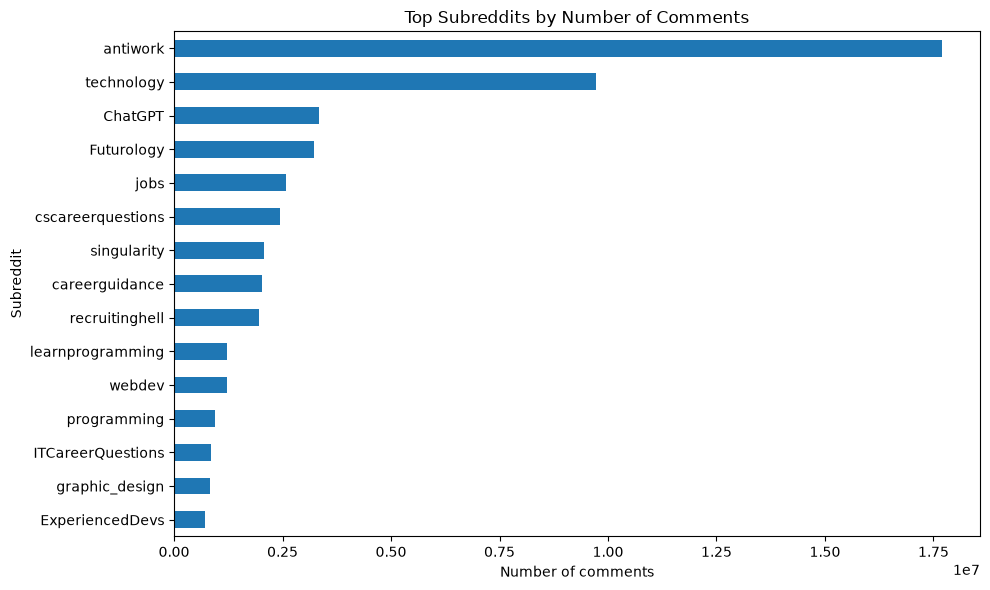

In [25]:
ax = submissions_by_subreddit.head(15).sort_values("submissions").plot(
    x="subreddit",
    y="submissions",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

ax.set_title("Top Subreddits by Number of Submissions")
ax.set_xlabel("Number of submissions")
ax.set_ylabel("Subreddit")

plt.tight_layout()
plt.show()

ax = comments_by_subreddit.head(15).sort_values("comments").plot(
    x="subreddit",
    y="comments",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

ax.set_title("Top Subreddits by Number of Comments")
ax.set_xlabel("Number of comments")
ax.set_ylabel("Subreddit")

plt.tight_layout()
plt.show()

### Interpretation

As we see, `antiwork` is the most active subreddit by a large margin in both submissions and comments.

The ranking changes for several other communities. `careerguidance` has the second-highest number of submissions, but it ranks much lower by comments. In contrast, `technology` has fewer submissions than several career-focused communities, but it is second by total number of comments.

This suggests that some communities are more active in creating new posts, while others generate longer or more intensive discussions around each post. For this reason, both submissions and comments are important for understanding activity in the dataset.

## 2.2 Subreddit activity over time

We now focus on the most active subreddits and examine how their activity changed over time.

By comparing their monthly activity, we look for noticeable peaks, declines, sudden changes, and differences in how individual communities developed between 2022 and 2024.

In [26]:
def monthly_activity_by_subreddit(files, chunksize=200_000):
    monthly_counts = {}

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["created_utc", "subreddit"],
            chunksize=chunksize,
            low_memory=False
        ):
            dates = pd.to_datetime(
                pd.to_numeric(chunk["created_utc"], errors="coerce"),
                unit="s",
                utc=True,
                errors="coerce"
            )

            months = (
                dates
                .dt.tz_localize(None)
                .dt.to_period("M")
                .astype(str)
            )

            temp = pd.DataFrame({
                "month": months,
                "subreddit": chunk["subreddit"]
            }).dropna()

            grouped = (
                temp
                .groupby(["month", "subreddit"])
                .size()
            )

            for (month, subreddit), count in grouped.items():
                key = (month, subreddit)
                monthly_counts[key] = monthly_counts.get(key, 0) + count

    return (
        pd.DataFrame(
            [
                {"month": month, "subreddit": subreddit, "count": count}
                for (month, subreddit), count in monthly_counts.items()
            ]
        )
        .sort_values(["month", "subreddit"])
        .reset_index(drop=True)
    )


monthly_subreddit_submissions = monthly_activity_by_subreddit(submission_files)
monthly_subreddit_comments = monthly_activity_by_subreddit(comment_files)

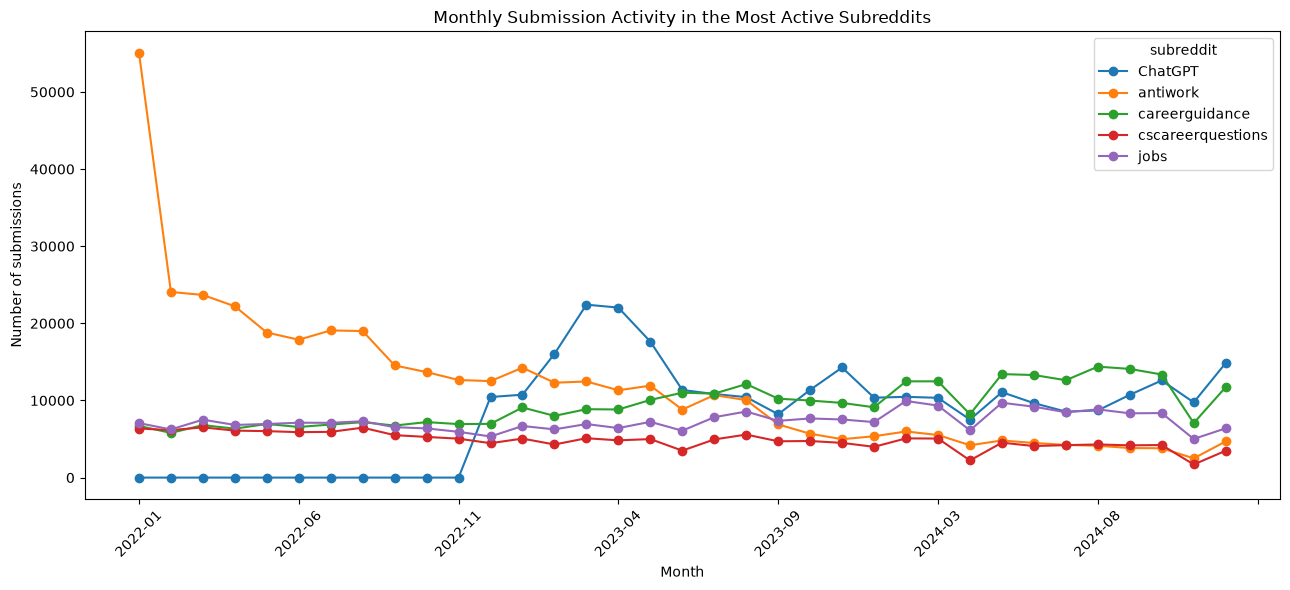

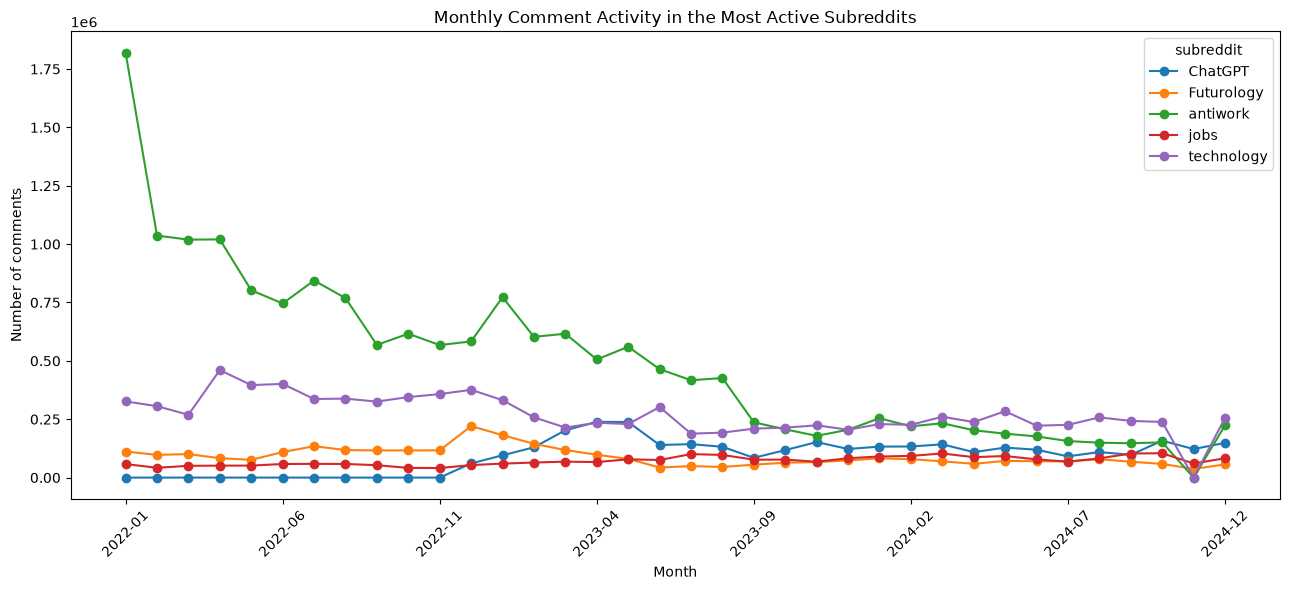

In [28]:
top_submission_subreddits = (
    submissions_by_subreddit
    .head(5)["subreddit"]
    .tolist()
)

top_comment_subreddits = (
    comments_by_subreddit
    .head(5)["subreddit"]
    .tolist()
)


submission_top_time = monthly_subreddit_submissions[
    monthly_subreddit_submissions["subreddit"].isin(top_submission_subreddits)
]

submission_pivot = submission_top_time.pivot(
    index="month",
    columns="subreddit",
    values="count"
).fillna(0)

ax = submission_pivot.plot(
    figsize=(13, 6),
    marker="o"
)

ax.set_title("Monthly Submission Activity in the Most Active Subreddits")
ax.set_xlabel("Month")
ax.set_ylabel("Number of submissions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


comment_top_time = monthly_subreddit_comments[
    monthly_subreddit_comments["subreddit"].isin(top_comment_subreddits)
]

comment_pivot = comment_top_time.pivot(
    index="month",
    columns="subreddit",
    values="count"
).fillna(0)

ax = comment_pivot.plot(
    figsize=(13, 6),
    marker="o"
)

ax.set_title("Monthly Comment Activity in the Most Active Subreddits")
ax.set_xlabel("Month")
ax.set_ylabel("Number of comments")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Interpretation 

The most active subreddits show very different activity patterns over time.

For submissions, `antiwork` starts at a very high level in early 2022 and then declines strongly throughout the period. At the same time, `ChatGPT` has almost no activity before late 2022, followed by a sharp increase at the end of 2022 and especially in early 2023. `careerguidance`, `jobs`, and `cscareerquestions` are more stable, although they also show moderate fluctuations over time.

The comment activity shows a similar contrast. `antiwork` dominates discussion in early 2022 but declines substantially over time, while `ChatGPT` appears later and grows after the end of 2022. `technology` remains one of the largest sources of comments throughout the period.

However, high activity may partly reflect subreddit size: larger communities naturally have more potential users who can create posts and comments. If differences in activity remain strong after adjusting for the number of subscribers, this would suggest that the pattern is related to community behavior rather than only to community size.

This is why we next compare activity relative to subreddit size.

## 2.3 Activity adjusted for subreddit size

In [34]:
# Use the already calculated monthly submission/comment counts

monthly_posts = monthly_subreddit_submissions.rename(
    columns={"count": "submissions"}
)

monthly_comments = monthly_subreddit_comments.rename(
    columns={"count": "comments"}
)

# We still need monthly subreddit size from submission metadata
def monthly_subreddit_size(files, chunksize=200_000):
    parts = []

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["created_utc", "subreddit", "subreddit_subscribers"],
            chunksize=chunksize,
            low_memory=False
        ):
            chunk["month"] = (
                pd.to_datetime(
                    pd.to_numeric(chunk["created_utc"], errors="coerce"),
                    unit="s",
                    utc=True,
                    errors="coerce"
                )
                .dt.tz_localize(None)
                .dt.to_period("M")
                .astype(str)
            )

            chunk = chunk.dropna(
                subset=["month", "subreddit", "subreddit_subscribers"]
            )

            monthly = (
                chunk.groupby(["month", "subreddit"])
                .agg(
                    subscribers=("subreddit_subscribers", "median")
                )
                .reset_index()
            )

            parts.append(monthly)

    combined = pd.concat(parts, ignore_index=True)

    return (
        combined
        .groupby(["month", "subreddit"])
        .agg(subscribers=("subscribers", "median"))
        .reset_index()
    )


monthly_subscribers = monthly_subreddit_size(submission_files)

# Combine posts and comments
monthly_activity = (
    monthly_posts
    .merge(
        monthly_comments,
        on=["month", "subreddit"],
        how="outer"
    )
    .fillna({"submissions": 0, "comments": 0})
)

monthly_activity["total_activity"] = (
    monthly_activity["submissions"]
    + monthly_activity["comments"]
)

# Add subreddit size
monthly_activity = monthly_activity.merge(
    monthly_subscribers,
    on=["month", "subreddit"],
    how="left"
)

monthly_activity = monthly_activity[
    monthly_activity["subscribers"] > 0
].copy()

# Posts + comments per 100,000 subscribers
monthly_activity["activity_per_100k"] = (
    monthly_activity["total_activity"]
    / monthly_activity["subscribers"]
    * 100_000
)

# Typical monthly normalized activity for every subreddit
normalized_summary = (
    monthly_activity
    .groupby("subreddit")
    .agg(
        median_monthly_activity_per_100k=("activity_per_100k", "median"),
        median_subscribers=("subscribers", "median")
    )
    .sort_values("median_monthly_activity_per_100k", ascending=False)
    .reset_index()
)

display(normalized_summary.head(15))

,subreddit,median_monthly_activity_per_100k,median_subscribers
0,ClaudeAI,30657.190176,4251.25
1,Layoffs,19512.195122,1936.00
2,antiwork,17744.880863,2667930.00
3,ExperiencedDevs,15899.619046,117037.00
4,ArtistLounge,12852.300156,131720.00
5,recruitinghell,11484.939102,496225.00
6,Anthropic,10309.278351,1577.00
7,claude,8000.000000,75.00
8,cscareerquestions,7237.130407,1023434.00
9,ITCareerQuestions,6937.090687,378873.00


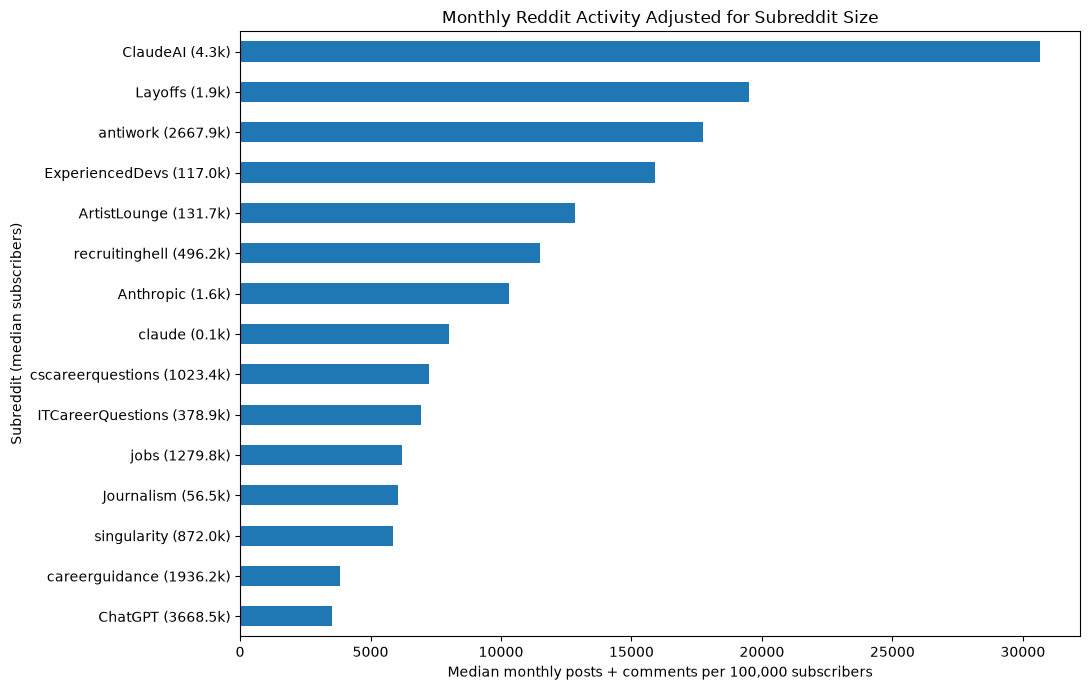

In [36]:
plot_data = normalized_summary.head(15).copy()

plot_data["label"] = (
    plot_data["subreddit"]
    + " ("
    + (plot_data["median_subscribers"] / 1000)
      .round(1)
      .astype(str)
    + "k)"
)

plot_data = plot_data.sort_values(
    "median_monthly_activity_per_100k"
)

ax = plot_data.plot(
    x="label",
    y="median_monthly_activity_per_100k",
    kind="barh",
    figsize=(11, 7),
    legend=False
)

ax.set_title("Monthly Reddit Activity Adjusted for Subreddit Size")
ax.set_xlabel("Median monthly posts + comments per 100,000 subscribers")
ax.set_ylabel("Subreddit (median subscribers)")

plt.tight_layout()
plt.show()

### Interpretation

We can see that some smaller communities, such as `ClaudeAI`, `Layoffs`, and `Anthropic`, have high activity relative to their size.

At the same time, larger subreddits such as `ChatGPT` and `careerguidance` have lower activity per 100,000 subscribers.

This shows that a high total number of posts and comments can partly be related to the size of the community, while some smaller communities are more active relative to their audience.

## 2.4 Author activity

We next examine how activity is distributed across users. The goal is to understand whether most content is created by many occasional users or by a smaller group of highly active authors.

In [37]:
def count_by_author(files, chunksize=200_000):
    counts = {}

    for file in files:
        for chunk in pd.read_csv(
            file,
            usecols=["author"],
            chunksize=chunksize,
            low_memory=False
        ):
            value_counts = chunk["author"].value_counts()

            for author, count in value_counts.items():
                counts[author] = counts.get(author, 0) + count

    return pd.Series(counts, name="count")


posts_per_author = count_by_author(submission_files)
comments_per_author = count_by_author(comment_files)

We also need to remove deleted users and obvious bot or moderation accounts before analyzing individual author activity.

In [41]:
non_user_accounts = [
    "[deleted]",
    "AutoModerator",
    "Flair_Helper",
    "FuturologyBot",
    "antiwork-ModTeam",
    "CSCQMods",
    "MAGIC_EYE_BOT"
]

posts_per_author = posts_per_author.drop(non_user_accounts, errors="ignore")
comments_per_author = comments_per_author.drop(non_user_accounts, errors="ignore")

In [42]:
top_post_authors = (
    posts_per_author
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_post_authors.columns = ["author", "submissions"]

top_comment_authors = (
    comments_per_author
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_comment_authors.columns = ["author", "comments"]

display(top_post_authors)
display(top_comment_authors)

,author,submissions
0,chrisdh79,3104
1,fagnerbrack,2629
2,Wagamaga,2611
3,Sorin61,2578
4,Pirapopnoticias,2516
5,ketralnis,2414
6,feross,2213
7,Maxie445,2069
8,sagarkangude11,1999
9,MetaKnowing,1553


,author,comments
0,desrtfx,19286
1,BrainWaveCC,16819
2,gregsw2000,14314
3,moreexclamationmarks,13675
4,Akimbo333,13658
5,sdmat,13479
6,ChildOf1970,13381
7,nutrecht,12022
8,MarcableFluke,11531
9,Which-Tomato-8646,10222


To better understand who contributes to the discussions, we first look at activity at the author level.

Earlier in the analysis, we identified all authors in the dataset, removed deleted users and obvious bot or moderation accounts, and then selected the top 10 authors by number of submissions and comments.

The most active commenters contributed much more content than the most active submission authors. While the top submission authors created around 2,000–3,000 posts, the most active commenters wrote more than 10,000 comments.

However, these top users represent only a small part of all authors. To understand the overall pattern of participation, we next group users by how many submissions or comments they created during the observed period.

In [44]:
def author_activity_groups(author_counts):
    groups = pd.cut(
        author_counts,
        bins=[0, 1, 5, 20, float("inf")],
        labels=["1", "2–5", "6–20", "20+"]
    )

    result = (
        groups
        .value_counts()
        .reindex(["1", "2–5", "6–20", "20+"])
        .rename("authors")
        .reset_index()
    )

    result.columns = ["activity_group", "authors"]

    return result


post_author_groups = author_activity_groups(posts_per_author)
comment_author_groups = author_activity_groups(comments_per_author)

display(post_author_groups)
display(comment_author_groups)

,activity_group,authors
0,1,754723
1,2–5,345108
2,6–20,49473
3,20+,6517


,activity_group,authors
0,1,1655072
1,2–5,1361453
2,6–20,735030
3,20+,417414


The groups represent authors who created exactly 1, 2–5, 6–20, or more than 20 submissions/comments during 2022–2024. We alos turned it into the graphic.

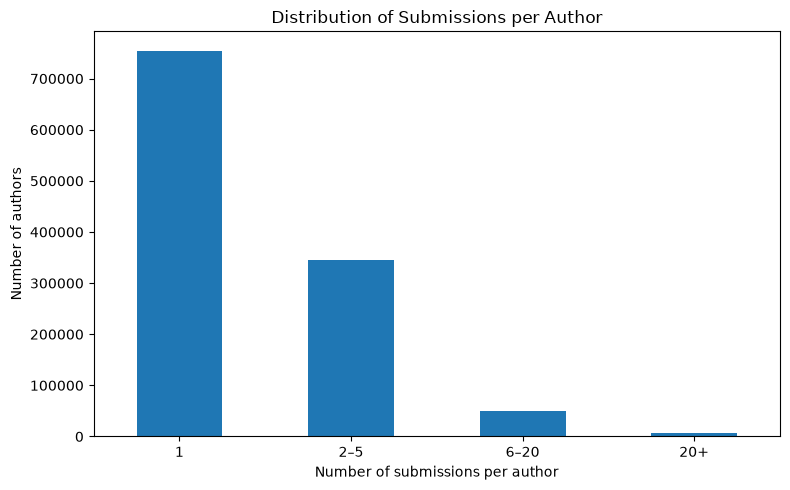

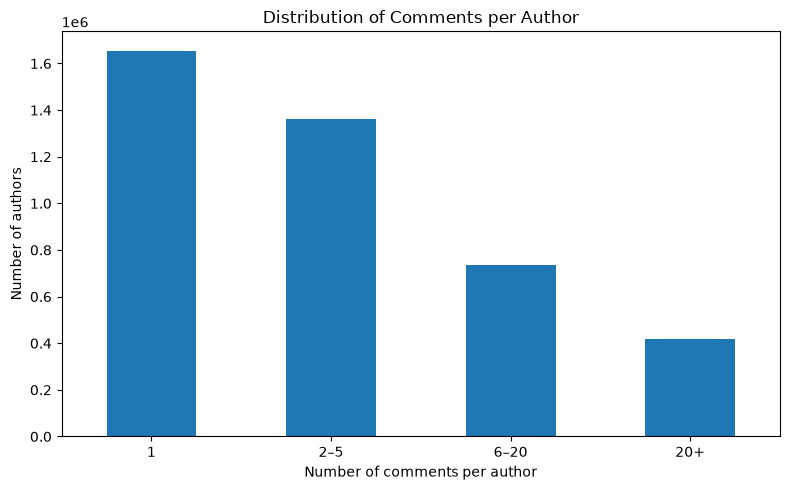

In [47]:
ax = post_author_groups.plot(
    x="activity_group",
    y="authors",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

ax.set_title("Distribution of Submissions per Author")
ax.set_xlabel("Number of submissions per author")
ax.set_ylabel("Number of authors")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ax = comment_author_groups.plot(
    x="activity_group",
    y="authors",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

ax.set_title("Distribution of Comments per Author")
ax.set_xlabel("Number of comments per author")
ax.set_ylabel("Number of authors")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

Most authors contribute only a small number of submissions or comments.

For submissions, the largest group consists of users who created only one post during 2022–2024, and the number of authors decreases strongly as posting frequency increases.

For comments, occasional users are still the largest group, but there are also many users who comment repeatedly. The groups with 6–20 and more than 20 comments are much larger than the corresponding groups for submissions.

This suggests that posting is more occasional, while commenting is a more frequent form of participation.

## 2.5 Engagement

After looking at where activity happens and who contributes to it, we now examine *how users react* to submissions.

For this, we use `score`, `num_comments`, and `upvote_ratio` to describe different aspects of engagement:
- `score` shows how positively or negatively a post was received;
- `num_comments` shows how much discussion a post generated;
- `upvote_ratio` shows the share of positive votes.

In [48]:
engagement_parts = []

for file in submission_files:
    part = pd.read_csv(
        file,
        usecols=[
            "id",
            "subreddit",
            "title",
            "score",
            "num_comments",
            "upvote_ratio"
        ],
        low_memory=False
    )

    engagement_parts.append(part)

engagement = pd.concat(engagement_parts, ignore_index=True)

In [51]:
# General engagement statistics
summary = engagement[
    ["score", "num_comments", "upvote_ratio"]
].describe()

display(
    summary.style.format({
        "score": "{:.2f}",
        "num_comments": "{:.2f}",
        "upvote_ratio": "{:.2f}"
    })
)

# Top 10 posts by score
top_score_posts = (
    engagement
    .sort_values("score", ascending=False)
    .head(10)[
        ["subreddit", "title", "score", "num_comments", "upvote_ratio"]
    ]
)

# Top 10 posts by number of comments
top_commented_posts = (
    engagement
    .sort_values("num_comments", ascending=False)
    .head(10)[
        ["subreddit", "title", "score", "num_comments", "upvote_ratio"]
    ]
)

display(top_score_posts)
display(top_commented_posts)

,score,num_comments,upvote_ratio
count,2860684.00,2860684.00,2860684.00
mean,126.92,16.99,0.86
std,1789.96,134.52,0.21
min,0.00,0.00,0.01
25%,1.00,1.00,0.76
50%,1.00,1.00,1.00
75%,3.00,5.00,1.00
max,167579.00,22685.00,1.00


,subreddit,title,score,num_comments,upvote_ratio
1246262,antiwork,This is so true....,167579,3710,0.82
312758,antiwork,"Telling them not to throw a party, throwing a ...",158115,3441,0.89
809374,antiwork,I feel like I can breathe again,149934,7106,0.87
589541,antiwork,Entire Starbucks Team Walks Out,148995,6332,0.84
2647994,recruitinghell,LMAO,144713,860,0.92
83875,antiwork,No shit?,143703,5101,0.89
540410,antiwork,I’m still in shock..,141066,4628,0.89
187600,technology,The teen famous for tracking Elon Musk's jet h...,137894,2010,0.89
140860,antiwork,No one wants to work. Our turnover is terrible.,136601,2344,0.91
1065671,antiwork,No Paid Sick Leave For You Railroad Workers Ei...,135522,2208,0.90


,subreddit,title,score,num_comments,upvote_ratio
643934,antiwork,I have mandatory work funtime after office hou...,20292,22685,0.85
2652241,jobs,Should I be embarrassed about being a 24yr old...,36274,19129,0.81
330260,technology,Twitter to accept Elon Musk’s $45 billion bid ...,63067,18776,0.82
92318,antiwork,Statement /r/Antiwork,0,16382,0.15
324894,technology,Netflix Officially Adding Commercials,68740,15707,0.73
970208,antiwork,"American's of Reddit, how do y'all stay sane w...",32737,15219,0.80
320320,antiwork,I laughed out loud at this email. Holy shit. L...,99508,13596,0.85
562738,antiwork,My boss (OK gun store) posted another notice t...,96488,13106,0.75
938765,antiwork,new rules at work… I’m turning in my 2 week no...,42040,12925,0.83
468420,antiwork,Are Americans OK?,48598,12275,0.71


### Interpretation

The first table summarizes overall engagement across all submissions using `score`, `num_comments`, and `upvote_ratio`.

The next two tables show the top 10 submissions with the highest score and the highest number of comments.

Most submissions receive relatively little engagement, while a small number of posts receive extremely high scores or generate very large discussions. The most highly scored posts and the most commented posts are not always the same, which shows that voting support and discussion intensity are different forms of engagement.

In [52]:
engagement_by_subreddit = (
    engagement
    .groupby("subreddit")
    .agg(
        median_score=("score", "median"),
        median_comments=("num_comments", "median"),
        median_upvote_ratio=("upvote_ratio", "median"),
        submissions=("id", "count")
    )
    .reset_index()
)

display(
    engagement_by_subreddit
    .sort_values("median_comments", ascending=False)
    .head(15)
)

,subreddit,median_score,median_comments,median_upvote_ratio,submissions
8,Layoffs,16.0,10.0,0.94,6014
4,ExperiencedDevs,1.0,8.0,0.92,22108
12,antiwork,5.0,4.0,0.95,416119
3,ClaudeAI,2.0,3.0,0.79,9815
1,ArtistLounge,1.0,3.0,1.00,54272
6,ITCareerQuestions,1.0,3.0,0.86,71692
24,recruitinghell,2.0,3.0,0.98,89169
7,Journalism,2.0,2.0,1.00,16883
5,Futurology,1.0,2.0,1.00,45194
20,graphic_design,1.0,2.0,1.00,88814


We next compare engagement across subreddits by looking at the median number of comments received by a submission in each community.

Using the median helps reduce the influence of a small number of extremely popular posts.

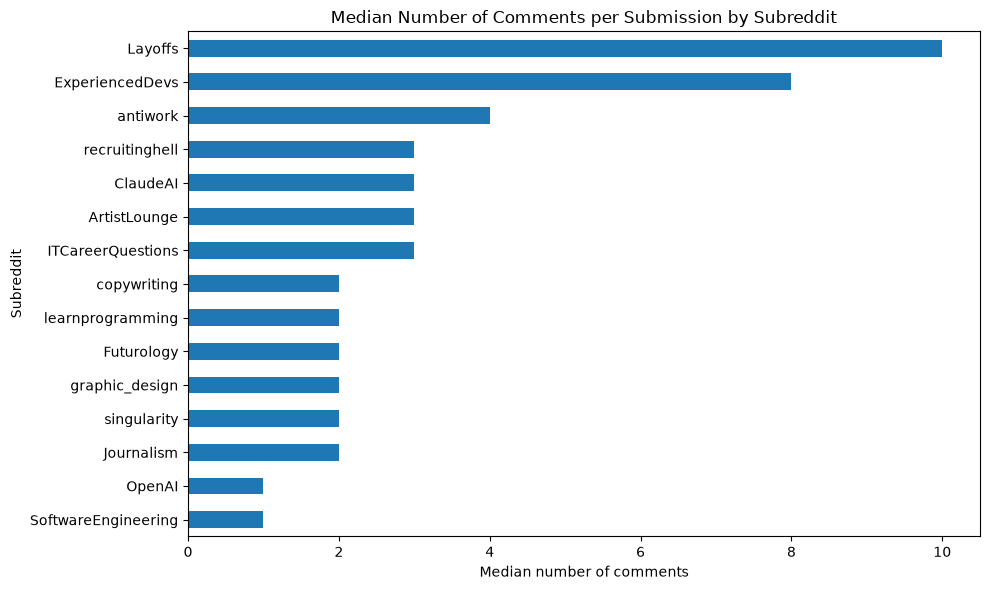

In [53]:
top_comments = (
    engagement_by_subreddit
    .sort_values("median_comments", ascending=False)
    .head(15)
    .sort_values("median_comments")
)

ax = top_comments.plot(
    x="subreddit",
    y="median_comments",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

ax.set_title("Median Number of Comments per Submission by Subreddit")
ax.set_xlabel("Median number of comments")
ax.set_ylabel("Subreddit")

plt.tight_layout()
plt.show()

### Interpretation

The chart shows that discussion intensity differs across communities.

`Layoffs` and `ExperiencedDevs` have the highest median number of comments per submission, which suggests that posts in these communities tend to generate more discussion. In contrast, many other subreddits receive only a few comments on a typical post.

Them, we also compare the typical submission score across subreddits.

The median score shows how strongly posts are usually supported by voting in each community, while reducing the influence of a small number of extremely popular posts.

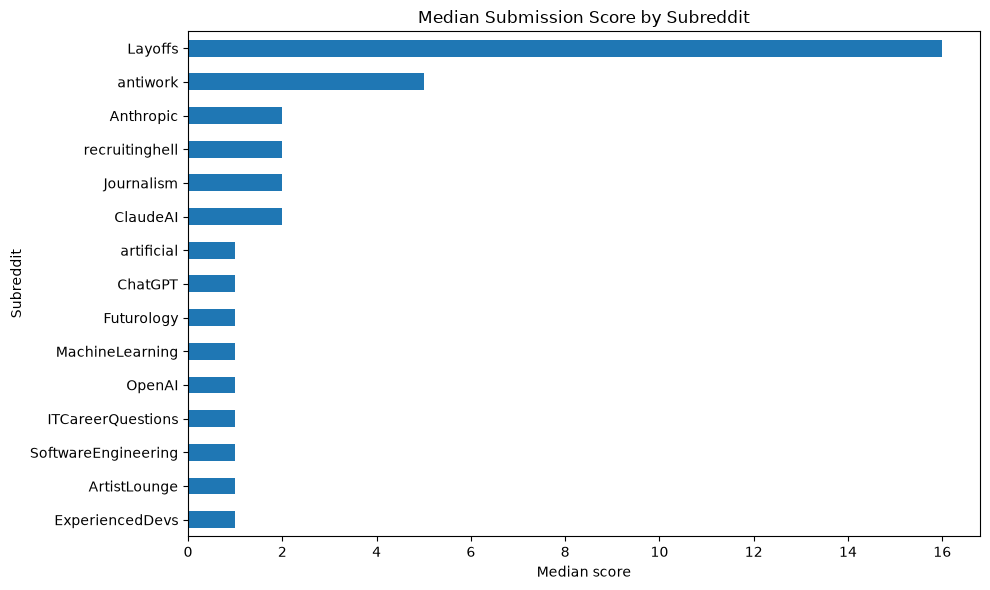

In [54]:
top_score = (
    engagement_by_subreddit
    .sort_values("median_score", ascending=False)
    .head(15)
    .sort_values("median_score")
)

ax = top_score.plot(
    x="subreddit",
    y="median_score",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

ax.set_title("Median Submission Score by Subreddit")
ax.set_xlabel("Median score")
ax.set_ylabel("Subreddit")

plt.tight_layout()
plt.show()

### Interpretation

`Layoffs` has the highest median submission score by a large margin, followed by `antiwork`.

Most other communities have much lower median scores, often around 1–2. This suggests that typical voting engagement differs substantially across subreddits.

## 2.6 Time of activity

We also examine when submissions are most frequently created.

Since `created_utc` is stored in UTC and user locations are unknown, the following patterns are interpreted in UTC time.

In [56]:
time_parts = []

for file in submission_files:
    part = pd.read_csv(
        file,
        usecols=["created_utc"],
        low_memory=False
    )

    time_parts.append(part)

time_activity = pd.concat(time_parts, ignore_index=True)

time_activity["datetime"] = pd.to_datetime(
    pd.to_numeric(time_activity["created_utc"], errors="coerce"),
    unit="s",
    utc=True,
    errors="coerce"
)

time_activity["hour"] = time_activity["datetime"].dt.hour
time_activity["day_of_week"] = time_activity["datetime"].dt.day_name()

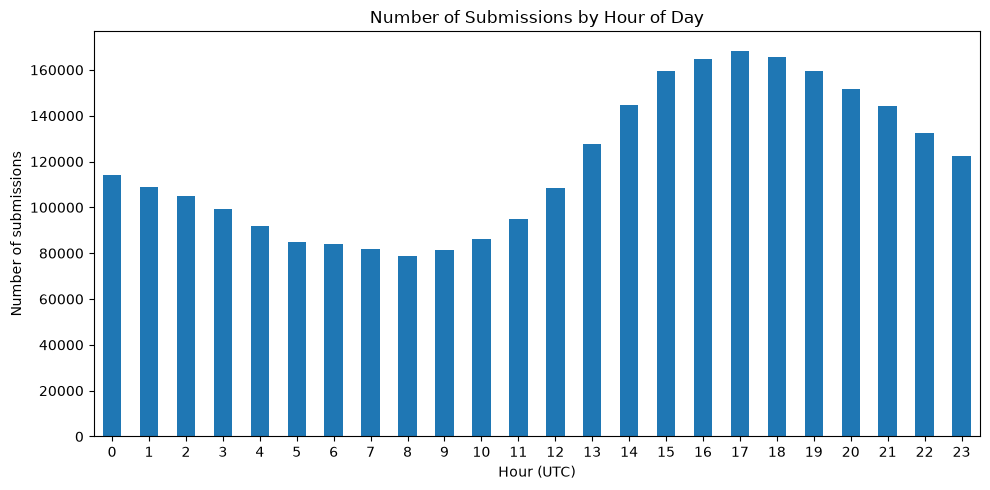

In [57]:
hourly_activity = (
    time_activity
    .groupby("hour")
    .size()
    .reset_index(name="submissions")
)

ax = hourly_activity.plot(
    x="hour",
    y="submissions",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

ax.set_title("Number of Submissions by Hour of Day")
ax.set_xlabel("Hour (UTC)")
ax.set_ylabel("Number of submissions")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

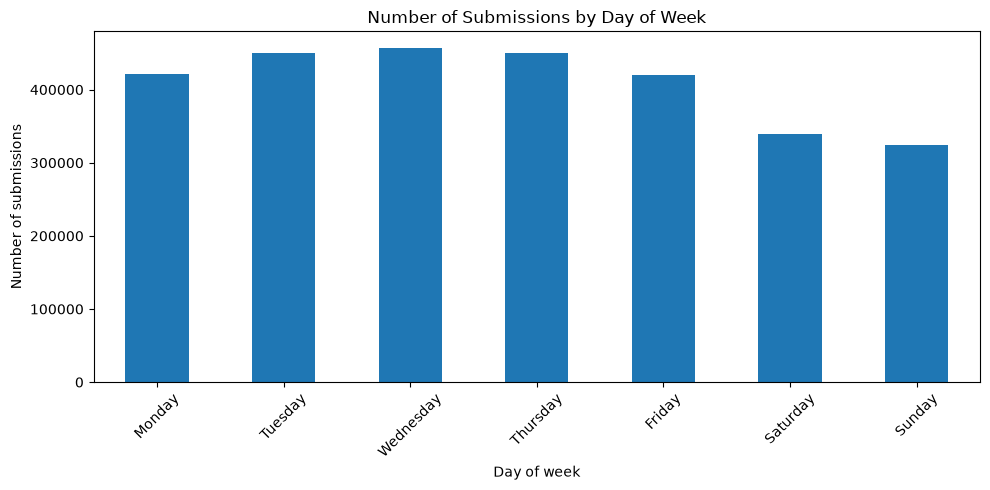

In [58]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_activity = (
    time_activity["day_of_week"]
    .value_counts()
    .reindex(day_order)
    .reset_index()
)

daily_activity.columns = ["day", "submissions"]

ax = daily_activity.plot(
    x="day",
    y="submissions",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

ax.set_title("Number of Submissions by Day of Week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Number of submissions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

Submission activity varies clearly by both hour of day and day of week.

The highest activity occurs in the late afternoon and early evening UTC, with a peak around 17:00 UTC. Activity is lowest during the morning hours.

By day of week, submissions are more frequent on weekdays, especially from Tuesday to Thursday, while activity drops noticeably on Saturday and Sunday.

Because timestamps are stored in UTC and users' local time zones are unknown, these patterns should be interpreted as global posting-time patterns rather than local user behavior.

# 3. Content Analysis

The previous sections described the structure of the dataset, subreddit activity, author participation, engagement, and posting-time patterns.

We now focus on the content of the discussions and examine how Reddit users talked about AI and employment between 2022 and 2024.

## 3.1 Identifying AI and employment-related discussions

The dataset contains all posts and comments from the selected subreddits, so we first identify the records that are relevant to both AI and employment.

For AI-focused communities, we search for employment-related terms. For other communities, we require both AI-related and employment-related terms to appear in the text.

In [2]:
ai_native_subreddits = {
    "chatgpt",
    "openai",
    "claudeai",
    "anthropic",
    "artificial",
    "singularity",
    "machinelearning"
}

ai_pattern = (
    r"\b(?:ai|artificial intelligence|chatgpt|openai|claude|anthropic|"
    r"gpt\w*|llm\w*|machine learning|copilot|gemini|generative ai|genai)\b"
)

employment_pattern = (
    r"\b(?:"
    r"job|jobs|career|careers|employment|unemployment|"
    r"employer|employee|employees|"
    r"hiring|hire|hired|recruiting|recruiter|"
    r"layoff|layoffs|laid off|"
    r"salary|salaries|wage|wages|"
    r"profession|professions|"
    r"junior|entry.level|new grad|graduate job|"
    r"job market|labor market|labour market|workforce|"
    r"job loss|lose my job|losing my job|"
    r"replace\w*.*job|job.*replace\w*|"
    r"career change|career transition|"
    r"reskill\w*|upskill\w*"
    r")\b"
)

In [3]:
relevant_parts = []

for file in submission_files:
    for chunk in pd.read_csv(
        file,
        usecols=[
            "id",
            "created_utc",
            "subreddit",
            "title",
            "selftext",
            "score",
            "num_comments"
        ],
        chunksize=100_000,
        low_memory=False
    ):
        chunk["title"] = chunk["title"].fillna("")
        chunk["selftext"] = chunk["selftext"].fillna("")

        text = chunk["title"] + " " + chunk["selftext"]

        ai_match = text.str.contains(
            ai_pattern,
            case=False,
            regex=True,
            na=False
        )

        employment_match = text.str.contains(
            employment_pattern,
            case=False,
            regex=True,
            na=False
        )

        is_ai_native = (
            chunk["subreddit"]
            .str.lower()
            .isin(ai_native_subreddits)
        )

        relevant = chunk[
            employment_match & (ai_match | is_ai_native)
        ].copy()

        relevant_parts.append(relevant)

ai_employment_posts = pd.concat(
    relevant_parts,
    ignore_index=True
)

print("Relevant AI + employment submissions:", len(ai_employment_posts))
display(ai_employment_posts.head(10))

Relevant AI + employment submissions: 40582


,created_utc,id,num_comments,score,selftext,subreddit,title
0,1.641005e+09,rt9lvq,1,1,"Hey everyone, \n\nI'm currently a college stud...",cscareerquestions,Super confused about what to do after I graduate
1,1.641008e+09,rtajtn,100,78,When will software jobs be automated? I am try...,singularity,When will software jobs be automated?
2,1.641029e+09,rtfy6c,1,1,\n\nI was looking forward to land a job in th...,cscareerquestions,Career path advice needed
3,1.641031e+09,rtg95g,12,16,Codexplainer is an AI tool to explain code in ...,webdev,This tool explains code in plain English on an...
4,1.641031e+09,rtgbq8,3,1,I'm a engineering graduate. I hold a Master's ...,careerguidance,Can anyone recommend a job that's suitable for...
5,1.641041e+09,rtist0,0,11,In my career transition to a job in AI after n...,antiwork,I just quit my job on new year's eve.
6,1.641047e+09,rtkb8a,10,4,"Hi everyone,\n\nHappy new year!\n\nSince the t...",graphic_design,Becoming a graphic designer without a formal e...
7,1.641048e+09,rtkm3t,2,2,,resumes,Master's of CS pursuing Machine Learning &amp;...
8,1.641058e+09,rto2cp,5,1,I'm currently doing a physics/math double majo...,cscareerquestions,Bare minimum for job in tech as a physics/math...
9,1.641093e+09,ru06dy,48,102,My job is to work with ML engineers and provid...,MachineLearning,[D] Coding Practices


In [15]:
pd.set_option("display.max_colwidth", 300)

sample_check = (
    ai_employment_posts[
        ["subreddit", "title", "selftext"]
    ]
    .sample(30, random_state=42)
)

display(sample_check)

,subreddit,title,selftext
36350,graphic_design,Enlighten me with this job position,"I had an interview, and I'm confused. I applied for the position of Marketing Specialist. I did a bit of research and saw that this real estate company doesn't have much visibility on social media. I thought, okay, maybe they'll at least hire more than just one person. But no, it will just be me..."
25531,artificial,Biden administration unveils new rules for federal government's use of AI,"- The Biden administration unveiled new policies to regulate the federal government's use of artificial intelligence, aiming to address concerns about workforce risks, privacy, and discrimination.\n\n- The policies require federal agencies to ensure AI use does not endanger Americans' rights and..."
29983,cscareerquestions,Is software engineering really as saturated as people say?,"So I clearly do not work in tech. I am a employee at Starbucks. I've started learning programming to give me something to do but I've found it exciting and easy to learn. Of course, like everyone it seems, I've thought ""why not do this as a career?""\n\n**I present the essay of my reasoning XD**\..."
20023,MachineLearning,[D] Exclusive: Sam Altman's ouster at OpenAI was precipitated by letter to board about AI breakthrough,"According to one of the sources, long-time executive Mira Murati told employees on Wednesday that a letter about the AI breakthrough called Q* (pronounced Q-Star), precipitated the board's actions.\n\nThe maker of ChatGPT had made progress on Q*, which some internally believe could be a breakthr..."
31245,ChatGPT,Best Software Training Institute in Hyderabad with Job Assistance,
15555,singularity,"Artificial Intelligence to Start ⁢Selling Cars by 2025, ​Says Swedish Company Phyron (sales professions are not safe)",
30390,careerguidance,The Future of Job Interviews: AI Copilots and Their Impact,[removed]
38689,singularity,Random guy says AGI by 2026,"Can we stop this nonsense, please?\n\nExtraordinary claims require extraordinary evidence. AGI is extra extraordinary. \n\nWhile LLMs have come a long way, predicting a specific AGI timeline requires a nuanced analysis of technological capabilities, research challenges, and expert consensus(whic..."
21464,jobs,Cameo to get hiring manager's attention?,Strong move or not worth the risk? Applying for a senior level job where I know from research that the hiring manager is a big sports fan. Should I email him a cameo of one of the players from his favorite team telling him to check out my resume to try and get past the AI / recruiter / formal pr...
31871,careerguidance,Computer vision career for a non-IT?,30m 🇮🇳from non it background!\nHello ! I am thinking of changing my career to tech industry!\nI have done bachelor's in management studies and have been working in insurance sales.\nI am planning to do mca distance that's the only tech master's degree I am eligible as I have maths at 10+2.\nI ...


### Semantic relevance classification

The keyword-based filtering produced 40,582 candidate submissions related to AI and employment.

However, keyword matching alone can include false positives. For example, a post may contain the word "job" in a different context or mention AI and careers without actually discussing the relationship between them.

Therefore, we use a language model to perform an additional semantic relevance check.

Each candidate post is classified into one of two categories:

- `RELEVANT` — the post meaningfully discusses AI in relation to employment, careers, hiring, job loss, workplace automation, professional skills, or similar topics.
- `NOT_RELEVANT` — the post was selected by the keyword filter but does not meaningfully discuss the relationship between AI and employment.

In [8]:
from ollama import chat

def classify_relevance(title, selftext):
    prompt = f"""
You are classifying Reddit posts for a research project about AI and employment.

Decide whether this post meaningfully discusses AI in relation to:
- jobs or employment
- careers
- hiring
- job loss or replacement
- professional skills
- workplace use of AI
- automation of work

Return exactly one label:
RELEVANT
NOT_RELEVANT

Title:
{title}

Post:
{selftext}
"""

    response = chat(
        model="qwen3.5:0.8b",
        messages=[
            {"role": "user", "content": prompt}
        ],
        options={
            "temperature": 0,
            "num_predict": 20
        }
    )

    return response.message.content.strip()

In [9]:
test_post = ai_employment_posts.sample(
    1,
    random_state=42
).iloc[0]

print("TITLE:")
print(test_post["title"])

print("\nCLASSIFICATION:")
print(
    classify_relevance(
        test_post["title"],
        test_post["selftext"]
    )
)

TITLE:
Enlighten me with this job position 

CLASSIFICATION:



In [ ]:
import os
import pandas as pd

output_file = "ai_employment_candidates_classified.csv"

if os.path.exists(output_file):
    classified_posts = pd.read_csv(output_file, low_memory=False)
    print("Continuing previous classification...")
else:
    classified_posts = ai_employment_posts.copy().reset_index(drop=True)
    classified_posts["llm_relevance"] = pd.NA
    print("Starting new classification...")

print("Total posts:", len(classified_posts))
print("Already classified:", classified_posts["llm_relevance"].notna().sum())

In [ ]:
for i in range(len(classified_posts)):

    # Skip posts that were already classified
    if pd.notna(classified_posts.at[i, "llm_relevance"]):
        continue

    title = classified_posts.at[i, "title"]
    selftext = classified_posts.at[i, "selftext"]

    try:
        label = classify_relevance(title, selftext)

        # Normalize model response
        label = label.strip().upper()

        if "NOT_RELEVANT" in label:
            label = "NOT_RELEVANT"
        elif "RELEVANT" in label:
            label = "RELEVANT"
        else:
            label = "UNKNOWN"

        classified_posts.at[i, "llm_relevance"] = label

    except Exception as e:
        print(f"Error at row {i}: {e}")
        classified_posts.at[i, "llm_relevance"] = "ERROR"

    # Save progress every 100 posts
    if (i + 1) % 100 == 0:
        classified_posts.to_csv(output_file, index=False)

        print(
            f"{i + 1}/{len(classified_posts)} completed"
        )

# Final save
classified_posts.to_csv(output_file, index=False)

print("Done!")
print(classified_posts["llm_relevance"].value_counts(dropna=False))

### Results of semantic relevance classification

After the language-model classification, we keep only submissions labeled as `RELEVANT`.

These posts form the final subset used for the content analysis. We first examine how many candidate posts were retained and then analyze how AI-employment discussions changed over time, across communities, and in terms of engagement and recurring themes.

In [ ]:
classified_posts = pd.read_csv(
    "ai_employment_candidates_classified.csv",
    low_memory=False
)

classified_posts["llm_relevance"] = (
    classified_posts["llm_relevance"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print(classified_posts["llm_relevance"].value_counts(dropna=False))

In [ ]:
relevant_posts = classified_posts[
    classified_posts["llm_relevance"] == "RELEVANT"
].copy()

print("Candidate posts:", len(classified_posts))
print("Relevant posts:", len(relevant_posts))

print(
    "Relevant share:",
    round(len(relevant_posts) / len(classified_posts) * 100, 2),
    "%"
)

## 3.2 Temporal Development of AI-Employment Discussions

We first examine how the volume of relevant AI-employment discussions changed between 2022 and 2024.

This allows us to identify periods when discussions about AI and work became more prominent and whether the growth was gradual or concentrated around particular periods.

In [ ]:
relevant_posts["created_utc"] = pd.to_datetime(
    relevant_posts["created_utc"],
    errors="coerce",
    utc=True
)

relevant_posts["month"] = (
    relevant_posts["created_utc"]
    .dt.to_period("M")
    .astype(str)
)

relevant_posts["year"] = relevant_posts["created_utc"].dt.year

In [ ]:
monthly_relevant = (
    relevant_posts
    .groupby("month")
    .size()
    .reset_index(name="posts")
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_relevant["month"],
    monthly_relevant["posts"],
    marker="o",
    markersize=3
)

plt.title("AI and Employment-Related Reddit Submissions Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Relevant Submissions")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
yearly_relevant = (
    relevant_posts
    .groupby("year")
    .size()
    .reset_index(name="posts")
)

display(yearly_relevant)

The monthly distribution shows how the volume of AI-employment discussions changed throughout the observation period.

The strongest increases and decreases are interpreted in the context of the development and public adoption of generative AI. Particular attention is given to changes after the release and rapid popularization of ChatGPT from late 2022 onward.

## 3.3 Accuracy of the Initial Keyword Filtering

The initial keyword-based filtering intentionally used relatively broad criteria in order to avoid missing relevant discussions.

We therefore compare the number of posts retained by the language model with the original candidate set. This provides an indication of how much noise was introduced by keyword matching alone.

In [ ]:
relevance_counts = (
    classified_posts["llm_relevance"]
    .value_counts()
    .reindex(["RELEVANT", "NOT_RELEVANT"], fill_value=0)
)

plt.figure(figsize=(7, 5))

relevance_counts.plot(kind="bar")

plt.title("Semantic Relevance of Keyword-Filtered Candidate Posts")
plt.xlabel("LLM Classification")
plt.ylabel("Number of Submissions")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 3.4 AI-Employment Discussions Across Subreddits

We next examine which communities contributed most to the relevant AI-employment discussions.

Because the dataset contains both technology-focused and career-focused communities, this comparison helps reveal whether AI-employment discussions were concentrated in explicitly AI-related subreddits or spread across broader professional communities.

In [ ]:
subreddit_relevant = (
    relevant_posts["subreddit"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

subreddit_relevant.plot(kind="barh")

plt.title("Subreddits with the Most AI-Employment Related Submissions")
plt.xlabel("Number of Relevant Submissions")
plt.ylabel("Subreddit")

plt.tight_layout()
plt.show()

In [ ]:
subreddit_quality = (
    classified_posts
    .assign(
        is_relevant=
        classified_posts["llm_relevance"].eq("RELEVANT")
    )
    .groupby("subreddit")
    .agg(
        candidates=("id", "size"),
        relevant=("is_relevant", "sum")
    )
    .reset_index()
)

subreddit_quality["relevant_share"] = (
    subreddit_quality["relevant"]
    / subreddit_quality["candidates"]
)

subreddit_quality = subreddit_quality[
    subreddit_quality["candidates"] >= 50
].sort_values(
    "relevant_share",
    ascending=False
)

display(subreddit_quality.head(20))

In [ ]:
plot_data = subreddit_quality.head(15).sort_values("relevant_share")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["subreddit"],
    plot_data["relevant_share"] * 100
)

plt.title("Share of Keyword Candidates Confirmed as Relevant")
plt.xlabel("Relevant Posts (%)")
plt.ylabel("Subreddit")

plt.tight_layout()
plt.show()

## 3.5 Engagement with AI-Employment Discussions

We also examine how users interacted with posts discussing AI and employment.

For submissions, engagement is measured using the Reddit score and the number of comments. These indicators capture two different reactions: voting support and discussion intensity.

In [ ]:
engagement_summary = relevant_posts[
    ["score", "num_comments"]
].describe()

display(engagement_summary)

In [ ]:
top_discussed = (
    relevant_posts[
        ["subreddit", "title", "score", "num_comments"]
    ]
    .sort_values(
        "num_comments",
        ascending=False
    )
    .head(10)
)

display(top_discussed)

In [ ]:
top_scored = (
    relevant_posts[
        ["subreddit", "title", "score", "num_comments"]
    ]
    .sort_values(
        "score",
        ascending=False
    )
    .head(10)
)

display(top_scored)

In [ ]:
subreddit_engagement = (
    relevant_posts
    .groupby("subreddit")
    .agg(
        posts=("id", "size"),
        median_score=("score", "median"),
        median_comments=("num_comments", "median")
    )
    .query("posts >= 50")
    .sort_values(
        "median_comments",
        ascending=False
    )
)

display(subreddit_engagement.head(20))

## 3.6 Main Themes in AI-Employment Discussions

After restricting the dataset to semantically relevant posts, we examine several recurring themes using keyword-based indicators.

The indicators are not treated as perfect semantic classifications. Instead, they provide transparent and reproducible measures of whether posts contain language associated with:

- job replacement and threat,
- personal employment anxiety,
- adaptation and reskilling,
- entry-level and junior employment concerns.

Because the analysis is applied only after semantic relevance filtering, these indicators operate on a much more focused subset than the original keyword search.

In [ ]:
relevant_posts["text"] = (
    relevant_posts["title"].fillna("").astype(str)
    + " "
    + relevant_posts["selftext"].fillna("").astype(str)
).str.lower()

In [ ]:
threat_pattern = (
    r"\b(?:"
    r"replace(?:d|ment|s|ing)?|"
    r"job loss|lose my job|losing my job|"
    r"take my job|take our jobs|"
    r"obsolete|redundant|"
    r"automation|automate(?:d|s|ing)?|"
    r"layoff|layoffs|laid off"
    r")\b"
)

relevant_posts["theme_threat"] = (
    relevant_posts["text"]
    .str.contains(
        threat_pattern,
        regex=True,
        na=False
    )
)

In [ ]:
personal_pattern = (
    r"\b(?:"
    r"my job|my career|my profession|"
    r"i am worried|i'm worried|"
    r"i am scared|i'm scared|"
    r"i fear|afraid|anxious|"
    r"lose my job|losing my job|"
    r"should i change career|"
    r"career change"
    r")\b"
)

relevant_posts["theme_personal"] = (
    relevant_posts["text"]
    .str.contains(
        personal_pattern,
        regex=True,
        na=False
    )
)

In [ ]:
adaptation_pattern = (
    r"\b(?:"
    r"reskill(?:ing|ed)?|"
    r"upskill(?:ing|ed)?|"
    r"learn ai|learning ai|"
    r"learn chatgpt|"
    r"use ai at work|using ai at work|"
    r"use chatgpt at work|"
    r"adapt(?:ing|ation|ed)?|"
    r"new skills|"
    r"career transition|"
    r"career change"
    r")\b"
)

relevant_posts["theme_adaptation"] = (
    relevant_posts["text"]
    .str.contains(
        adaptation_pattern,
        regex=True,
        na=False
    )
)

In [ ]:
entry_level_pattern = (
    r"\b(?:"
    r"junior|entry.level|entry level|"
    r"new grad|graduate job|graduate role|"
    r"internship|internships|intern|"
    r"first job|starting my career"
    r")\b"
)

relevant_posts["theme_entry_level"] = (
    relevant_posts["text"]
    .str.contains(
        entry_level_pattern,
        regex=True,
        na=False
    )
)

## 3.7 Overall Theme Distribution

We next compare how frequently the four main themes appear among relevant AI-employment submissions.

In [ ]:
theme_counts = pd.Series({
    "Threat / replacement":
        relevant_posts["theme_threat"].sum(),

    "Personal concern":
        relevant_posts["theme_personal"].sum(),

    "Adaptation / reskilling":
        relevant_posts["theme_adaptation"].sum(),

    "Entry-level concern":
        relevant_posts["theme_entry_level"].sum()
}).sort_values()

plt.figure(figsize=(9, 5))

theme_counts.plot(kind="barh")

plt.title("Recurring Themes in AI-Employment Discussions")
plt.xlabel("Number of Relevant Submissions")
plt.ylabel("Theme")

plt.tight_layout()
plt.show()

In [ ]:
theme_share = (
    theme_counts
    / len(relevant_posts)
    * 100
)

display(
    theme_share
    .sort_values(ascending=False)
    .round(2)
)

## 3.8 How Themes Changed Over Time

To examine whether the character of AI-employment discussions changed between 2022 and 2024, we calculate the monthly share of posts associated with each theme.

Using shares rather than raw counts makes it easier to distinguish changes in topic composition from changes in the overall volume of Reddit activity.

In [ ]:
monthly_themes = (
    relevant_posts
    .groupby("month")
    .agg(
        total_posts=("id", "size"),
        threat=("theme_threat", "sum"),
        personal=("theme_personal", "sum"),
        adaptation=("theme_adaptation", "sum"),
        entry_level=("theme_entry_level", "sum")
    )
    .reset_index()
)

for column in [
    "threat",
    "personal",
    "adaptation",
    "entry_level"
]:
    monthly_themes[column + "_share"] = (
        monthly_themes[column]
        / monthly_themes["total_posts"]
        * 100
    )

display(monthly_themes.head())

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_themes["month"],
    monthly_themes["threat_share"]
)

plt.title(
    "Share of AI-Employment Posts Discussing Job Threat or Replacement"
)
plt.xlabel("Month")
plt.ylabel("Posts Mentioning Threat / Replacement (%)")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_themes["month"],
    monthly_themes["personal_share"]
)

plt.title(
    "Share of AI-Employment Posts Expressing Personal Employment Concern"
)
plt.xlabel("Month")
plt.ylabel("Posts with Personal Concern (%)")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_themes["month"],
    monthly_themes["adaptation_share"]
)

plt.title(
    "Share of AI-Employment Posts Discussing Adaptation or Reskilling"
)
plt.xlabel("Month")
plt.ylabel("Posts Mentioning Adaptation (%)")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_themes["month"],
    monthly_themes["entry_level_share"]
)

plt.title(
    "Share of AI-Employment Posts Discussing Entry-Level Employment"
)
plt.xlabel("Month")
plt.ylabel("Posts Mentioning Entry-Level Concerns (%)")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## 3.9 Career vs AI / Technology Communities

The dataset contains both career-oriented communities and AI or technology-oriented communities.

We therefore compare whether the themes of employment threat, personal concern, adaptation, and entry-level employment appear differently across these community types.

In [ ]:
career_subreddits = {
    "careerguidance",
    "jobs",
    "cscareerquestions",
    "experienceddevs",
    "recruitinghell",
    "layoffs"
}

ai_tech_subreddits = {
    "chatgpt",
    "openai",
    "claudeai",
    "anthropic",
    "artificial",
    "singularity",
    "machinelearning",
    "technology",
    "futurology"
}

In [ ]:
def subreddit_group(subreddit):
    name = str(subreddit).lower()

    if name in career_subreddits:
        return "Career communities"

    if name in ai_tech_subreddits:
        return "AI / technology communities"

    return "Other communities"


relevant_posts["community_group"] = (
    relevant_posts["subreddit"]
    .apply(subreddit_group)
)

In [ ]:
community_summary = (
    relevant_posts
    .groupby("community_group")
    .agg(
        posts=("id", "size"),
        threat_share=("theme_threat", "mean"),
        personal_share=("theme_personal", "mean"),
        adaptation_share=("theme_adaptation", "mean"),
        entry_level_share=("theme_entry_level", "mean")
    )
)

for column in [
    "threat_share",
    "personal_share",
    "adaptation_share",
    "entry_level_share"
]:
    community_summary[column] *= 100

display(
    community_summary.round(2)
)

In [ ]:
plot_data = (
    community_summary[
        [
            "threat_share",
            "personal_share",
            "adaptation_share",
            "entry_level_share"
        ]
    ]
    .T
)

plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("AI-Employment Themes Across Community Types")
plt.xlabel("Theme")
plt.ylabel("Relevant Posts (%)")
plt.xticks(rotation=20)
plt.legend(title="Community Type")

plt.tight_layout()
plt.show()

## 3.10 Employment Threat and User Engagement

Finally, we examine whether posts discussing job replacement, automation, or employment threat receive different levels of engagement than other relevant AI-employment posts.

We focus primarily on median score and median number of comments because both engagement variables are strongly skewed by a small number of highly popular submissions.

In [ ]:
threat_engagement = (
    relevant_posts
    .groupby("theme_threat")
    .agg(
        posts=("id", "size"),
        median_score=("score", "median"),
        median_comments=("num_comments", "median"),
        mean_score=("score", "mean"),
        mean_comments=("num_comments", "mean")
    )
)

threat_engagement.index = [
    "Other relevant posts",
    "Threat / replacement posts"
]

display(
    threat_engagement.round(2)
)

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    threat_engagement.index,
    threat_engagement["median_comments"]
)

plt.title(
    "Median Discussion Engagement by Employment-Threat Content"
)
plt.ylabel("Median Number of Comments")
plt.xlabel("")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    threat_engagement.index,
    threat_engagement["median_score"]
)

plt.title(
    "Median Submission Score by Employment-Threat Content"
)
plt.ylabel("Median Score")
plt.xlabel("")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# 4 Interesting Findings

The previous analyses allow us to connect structural activity patterns with the content of AI-employment discussions.

In this section, we summarize the most important patterns observed in the data and relate them to the original research question and hypotheses.

The final interpretation focuses on:

- whether AI-employment discussions became more prominent after the emergence of widely used generative AI systems;
- whether discussions shifted from abstract concerns toward personal employment anxiety;
- differences between career-oriented and AI/technology-oriented communities;
- whether adaptation and reskilling became more prominent over time;
- whether entry-level employment concerns increased;
- whether employment-threat posts generated stronger user engagement.

# 5 Limitations

Several limitations should be considered when interpreting the results.

First, the dataset represents Reddit activity rather than the broader population. Reddit users are not representative of all workers, and the selected subreddits may attract people who are particularly interested in technology, careers, employment problems, or AI.

Second, the initial identification of AI-employment discussions relies on keyword filtering. Although semantic relevance classification is used to reduce false positives, some relevant posts may still be missed by the initial keyword criteria.

Third, the thematic indicators for threat, personal concern, adaptation, and entry-level employment are based on explicit keyword patterns. They provide transparent and reproducible measures, but they cannot capture all nuances of the language used in the discussions.

Fourth, Reddit score and number of comments measure platform engagement rather than the real-world importance of an issue.

Finally, changes in activity may partly reflect changes in subreddit size, Reddit usage, or data collection coverage rather than changes in attitudes alone.

# 6 Conclusion

This exploratory analysis examines how discussions about AI and employment changed across technology- and career-related Reddit communities between 2022 and 2024.

The analysis combines structural Reddit activity, semantic relevance filtering, temporal patterns, community comparisons, engagement measures, and recurring employment-related themes.

The final results are interpreted with particular attention to changes in perceived job threat, personal career anxiety, adaptation and reskilling, and concerns about entry-level employment.

Overall, the analysis provides a data-driven view of how online discussions about AI moved beyond purely technological interest and became connected to broader questions about careers and the future of work.